# Data Collection and Preparation:
- ingesting the data in appropriate format (Unsere Jungs fragen: [1,2,3,4] -> [1,2] + [3], [2,3] + [4]) + fragen: was die anderen unter data ingestion verstehen? (Beide Datensätze mergen?)
- checking for missing or erroneous data
- cleaning your dataset

In [2]:
import pandas as pd

In [ ]:
# Ingesting the data
data_weather = pd.read_csv("../data/weather_burbank_airport.csv")


data_charge = pd.read_csv("../data/charging_sessions.csv")

In [14]:
# Get a brief overview
data_weather.head(3)

,city,timestamp,temperature,cloud_cover,cloud_cover_description,pressure,windspeed,precipitation,felt_temperature
0,Burbank,2018-01-01 08:53:00,9.0,33.0,Fair,991.75,9.0,0.0,8.0
1,Burbank,2018-01-01 09:53:00,9.0,33.0,Fair,992.08,0.0,0.0,9.0
2,Burbank,2018-01-01 10:53:00,9.0,21.0,Haze,992.08,0.0,0.0,9.0


In [13]:
# Get a brief overview
data_charge.head(3)

,Unnamed: 0,id,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs
connectionTime,,,,,,,,,,,,
2020-01-02 13:08:54+00:00,0,5e23b149f9af8b5fe4b973cf,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,25.016,1_1_179_810_2020-01-02 13:08:53.870034,1,AG-3F30,1-1-179-810,America/Los_Angeles,194.0,"[{'WhPerMile': 250, 'kWhRequested': 25.0, 'mil..."
2020-01-02 13:36:50+00:00,1,5e23b149f9af8b5fe4b973d0,2020-01-02 22:38:21+00:00,2020-01-02 20:18:05+00:00,33.097,1_1_193_825_2020-01-02 13:36:49.599853,1,AG-1F01,1-1-193-825,America/Los_Angeles,4275.0,"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'mil..."
2020-01-02 13:56:35+00:00,2,5e23b149f9af8b5fe4b973d1,2020-01-03 00:39:22+00:00,2020-01-02 16:35:06+00:00,6.521,1_1_193_829_2020-01-02 13:56:35.214993,1,AG-1F03,1-1-193-829,America/Los_Angeles,344.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."


In [ ]:
# Get a brief overview
data_charge.describe()

,Unnamed: 0,kWhDelivered,siteID,userID
count,66450.000000,66450.000000,66450.000000,49187.000000
mean,4726.102062,11.787916,1.472656,1800.494582
std,3568.025394,10.314789,0.499256,2617.548614
min,0.000000,0.501000,1.000000,1.000000
25%,1845.000000,5.097000,1.000000,431.000000
50%,3960.000000,9.140000,1.000000,818.000000
75%,7027.000000,14.183000,2.000000,1805.000000
max,15291.000000,108.797242,2.000000,19923.000000


In [ ]:
# Get a brief overview
data_charge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66450 entries, 0 to 66449
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        66450 non-null  int64  
 1   id                66450 non-null  object 
 2   connectionTime    66450 non-null  object 
 3   disconnectTime    66450 non-null  object 
 4   doneChargingTime  62362 non-null  object 
 5   kWhDelivered      66450 non-null  float64
 6   sessionID         66450 non-null  object 
 7   siteID            66450 non-null  int64  
 8   spaceID           66450 non-null  object 
 9   stationID         66450 non-null  object 
 10  timezone          66450 non-null  object 
 11  userID            49187 non-null  float64
 12  userInputs        49187 non-null  object 
dtypes: float64(2), int64(2), object(9)
memory usage: 6.6+ MB


In [ ]:
# Parse the datetime
data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])
data_charge = data_charge.set_index("connectionTime")

In [33]:
data_charge["userInputs"].iloc[1]

"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'milesRequested': 250, 'minutesAvailable': 595, 'modifiedAt': 'Thu, 02 Jan 2020 13:37:11 GMT', 'paymentRequired': True, 'requestedDeparture': 'Thu, 02 Jan 2020 23:31:50 GMT', 'userID': 4275}]"

In [45]:
data_charge["userInputs_parsed"].iloc[1]

"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'milesRequested': 250, 'minutesAvailable': 595, 'modifiedAt': 'Thu, 02 Jan 2020 13:37:11 GMT', 'paymentRequired': True, 'requestedDeparture': 'Thu, 02 Jan 2020 23:31:50 GMT', 'userID': 4275}]"

In [44]:
literal_eval(data_charge["userInputs_parsed"].iloc[1])

[{'WhPerMile': 280,
  'kWhRequested': 70.0,
  'milesRequested': 250,
  'minutesAvailable': 595,
  'modifiedAt': 'Thu, 02 Jan 2020 13:37:11 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Thu, 02 Jan 2020 23:31:50 GMT',
  'userID': 4275}]

In [36]:
import ast

In [51]:
data_charge["userInputs_parsed"].iloc[1]

"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'milesRequested': 250, 'minutesAvailable': 595, 'modifiedAt': 'Thu, 02 Jan 2020 13:37:11 GMT', 'paymentRequired': True, 'requestedDeparture': 'Thu, 02 Jan 2020 23:31:50 GMT', 'userID': 4275}]"

In [52]:
data_charge["userInputs_parsed_2"] = data_charge["userInputs_parsed"].apply(ast.literal_eval)

ValueError: malformed node or string: <_ast.Name object at 0x000001FD5A9AFE10>

In [ ]:
# Parse the userInputs column of data_charge
from ast import literal_eval

data_charge["userInputs_parsed"] = data_charge.userInputs.apply(lambda x: str(x))
# data_charge["userInputs_parsed"] = data_charge.userInputs.apply(lambda x: literal_eval(x))
# data_charge.userInputs.apply(lambda x: literal_eval(str(x)))

# Try to find missing or erroneous data

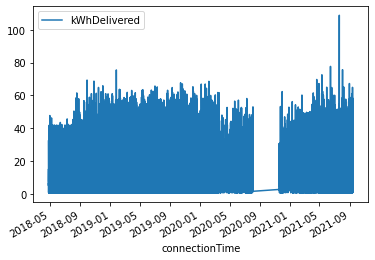

In [11]:
data_charge[["kWhDelivered"]].plot()

### Needed to remove possible outlier since one data point varies alot from the rest

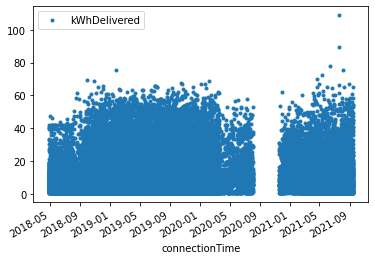

In [12]:
data_charge[["kWhDelivered"]].plot(style=".")

### Insight: Missing data

### 
